# SynchroGrid
## Adaptive Multi-Agent Traffic Optimization Simulator

A simulation of an urban road network containing autonomous vehicles, adaptive traffic lights, congestion, and emergency vehicles.

### Experiment
Compare three traffic-control strategies under identical traffic demand:

1. **Fixed Control** - traditional fixed-duration signals.
2. **Adaptive Control** - signal timing responds to queue lengths.
3. **Pressure Control** - selects signal phases using network pressure, queue imbalance, and emergency priority.

### Metrics
- Average vehicle waiting time
- Maximum queue length
- Completed trips
- Average travel time
- Total distance
- Emergency response time

The notebook is intentionally self-contained so the simulation can be modified and extended later.


=== SynchroGrid Experiment ===

FIXED
  Spawned:              87
  Completed:            85
  Completion rate:      97.70%
  Average wait:         11.05
  Average travel time:  14.34
  Maximum queue:        7
  Emergency completed:  0

ADAPTIVE
  Spawned:              76
  Completed:            74
  Completion rate:      97.37%
  Average wait:         6.77
  Average travel time:  10.26
  Maximum queue:        6
  Emergency completed:  0

PRESSURE
  Spawned:              80
  Completed:            77
  Completion rate:      96.25%
  Average wait:         3.74
  Average travel time:  6.96
  Maximum queue:        4
  Emergency completed:  0



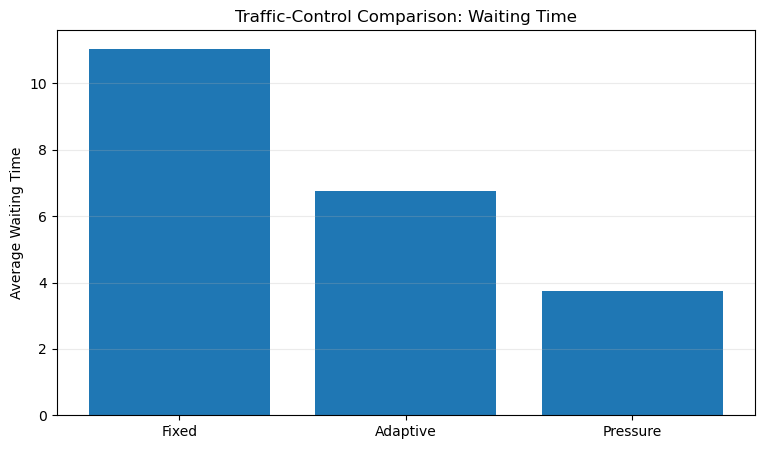

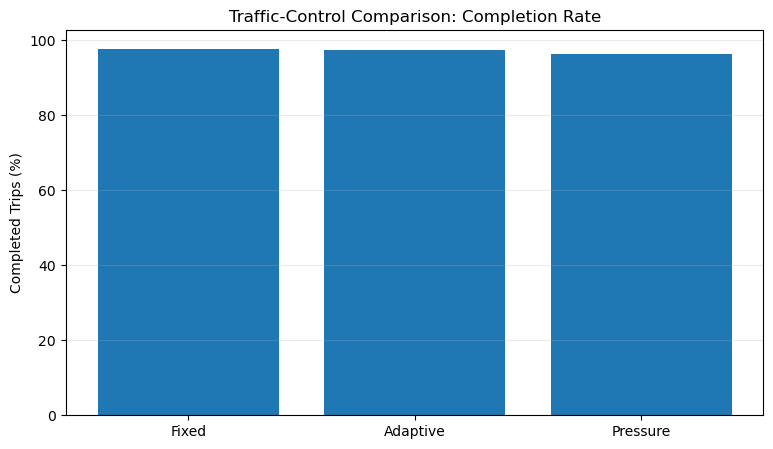

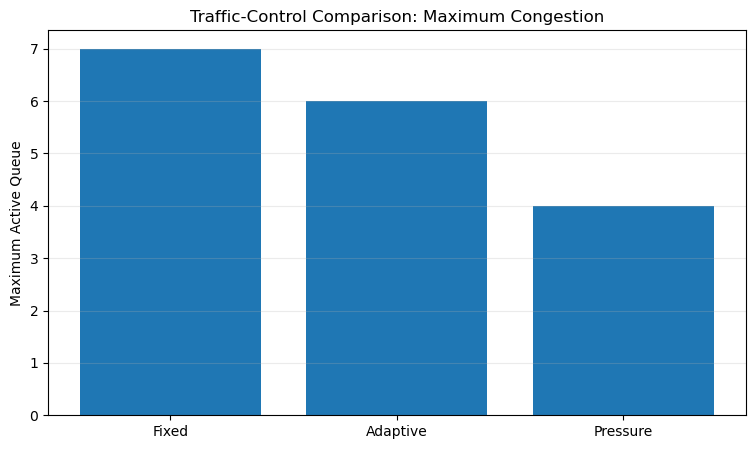

Visualization run:
{'strategy': 'pressure', 'spawned': 26, 'completed': 25, 'completion_rate': 0.9615384615384616, 'avg_wait': 5.8, 'avg_travel': 9.36, 'avg_distance': 3.56, 'max_queue': 5, 'emergency_completed': 0, 'emergency_avg_time': 0}


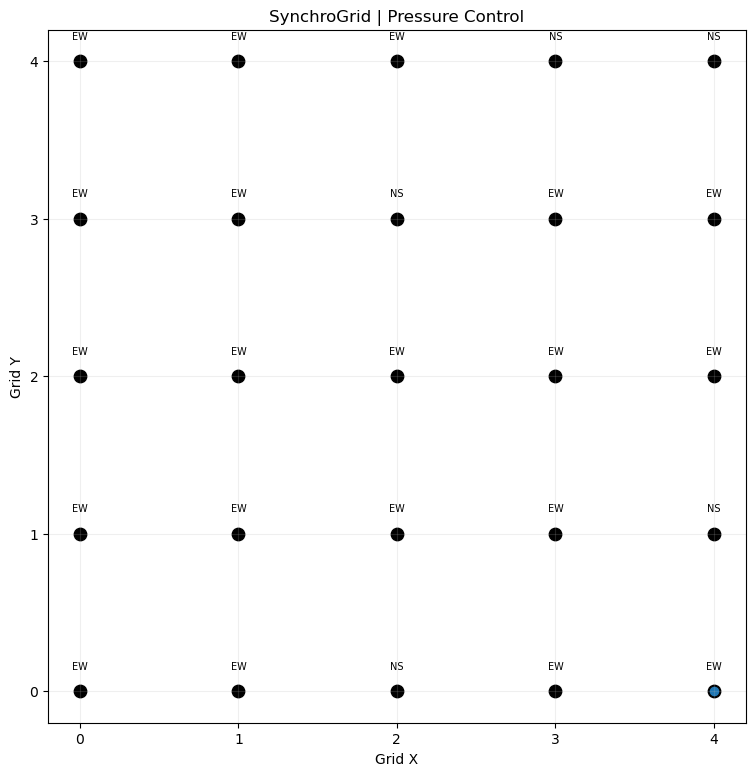

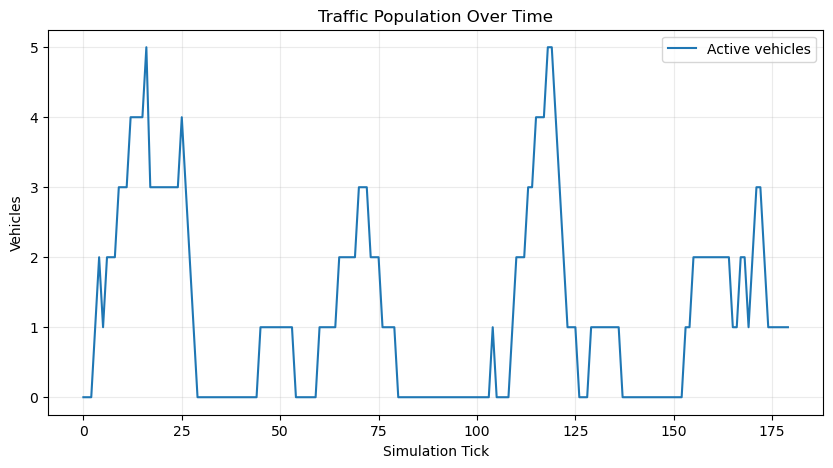

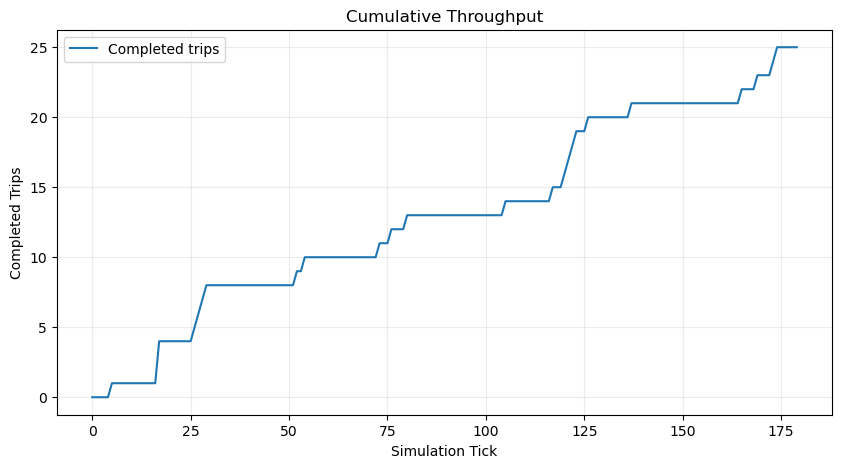

=== Multi-Run Benchmark ===

FIXED
  completion_rate   : 0.971 ± 0.023
  avg_wait          : 10.896 ± 1.056
  avg_travel        : 14.230 ± 1.161
  max_queue         : 8.100 ± 1.758

ADAPTIVE
  completion_rate   : 0.977 ± 0.015
  avg_wait          : 6.466 ± 0.545
  avg_travel        : 9.903 ± 0.571
  max_queue         : 5.800 ± 0.872

PRESSURE
  completion_rate   : 0.993 ± 0.009
  avg_wait          : 4.148 ± 0.469
  avg_travel        : 7.554 ± 0.603
  max_queue         : 4.700 ± 0.640

=== Best Observed Runs ===
Lowest average wait: pressure (3.43)
Highest completion: fixed (100.00%)


In [1]:

import random
import math
from dataclasses import dataclass, field
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

GRID_SIZE = 5
ROAD_LENGTH = 100
TICK_LIMIT = 500

ARRIVAL_RATE = 0.18
EMERGENCY_RATE = 0.008

VEHICLE_SPEED = 3.0
EMERGENCY_SPEED = 4.5

MIN_GREEN = 8
MAX_GREEN = 28
YELLOW_TIME = 3

# Cardinal directions
NORTH, EAST, SOUTH, WEST = range(4)

DIRECTIONS = {
    NORTH: (0, 1),
    EAST: (1, 0),
    SOUTH: (0, -1),
    WEST: (-1, 0),
}

OPPOSITE = {
    NORTH: SOUTH,
    EAST: WEST,
    SOUTH: NORTH,
    WEST: EAST,
}


# ------------------------------------------------------------
# Data models
# ------------------------------------------------------------

@dataclass
class Vehicle:
    vehicle_id: int
    origin: tuple
    destination: tuple
    position: tuple
    route: list
    emergency: bool = False
    speed: float = VEHICLE_SPEED
    route_index: int = 0
    waiting_time: float = 0.0
    travel_time: float = 0.0
    distance: float = 0.0
    completed: bool = False

    def step_time(self):
        self.travel_time += 1


@dataclass
class TrafficLight:
    intersection: tuple
    phase: int = EAST
    phase_time: int = 0
    cycle: int = 0

    def allowed(self, direction):
        # Each phase allows one axis at a time.
        if self.phase in (EAST, WEST):
            return direction in (EAST, WEST)
        return direction in (NORTH, SOUTH)

    def advance(self, duration):
        self.phase_time += 1
        if self.phase_time >= duration:
            self.phase = (self.phase + 1) % 4
            self.phase_time = 0
            self.cycle += 1


# ------------------------------------------------------------
# Road network
# ------------------------------------------------------------

class City:
    def __init__(self, size=GRID_SIZE):
        self.size = size
        self.intersections = [
            (x, y)
            for x in range(size)
            for y in range(size)
        ]

        self.lights = {
            node: TrafficLight(node)
            for node in self.intersections
        }

    def neighbors(self, node):
        x, y = node
        result = []

        for direction, (dx, dy) in DIRECTIONS.items():
            nx, ny = x + dx, y + dy

            if 0 <= nx < self.size and 0 <= ny < self.size:
                result.append(((nx, ny), direction))

        return result

    def shortest_route(self, start, goal):
        # BFS is sufficient because every road segment has equal cost.
        queue = deque([start])
        parent = {start: None}

        while queue:
            node = queue.popleft()

            if node == goal:
                break

            for neighbor, _ in self.neighbors(node):
                if neighbor not in parent:
                    parent[neighbor] = node
                    queue.append(neighbor)

        if goal not in parent:
            return []

        path = []
        node = goal

        while node is not None:
            path.append(node)
            node = parent[node]

        return path[::-1]

    def direction_between(self, a, b):
        dx = b[0] - a[0]
        dy = b[1] - a[1]

        for direction, vector in DIRECTIONS.items():
            if vector == (dx, dy):
                return direction

        return None


# ------------------------------------------------------------
# Traffic controller
# ------------------------------------------------------------

class TrafficController:
    def __init__(self, city, strategy="fixed"):
        self.city = city
        self.strategy = strategy
        self.history = []

    def queue_pressure(self, intersection, vehicles):
        pressure = {d: 0 for d in DIRECTIONS}

        for vehicle in vehicles:
            if vehicle.completed:
                continue

            if not vehicle.route:
                continue

            idx = vehicle.route_index

            if idx >= len(vehicle.route) - 1:
                continue

            current = vehicle.route[idx]

            if current != intersection:
                continue

            next_node = vehicle.route[idx + 1]
            direction = self.city.direction_between(
                current, next_node
            )

            if direction is not None:
                pressure[direction] += 2 if vehicle.emergency else 1

        return pressure

    def choose_duration(self, light, vehicles):
        if self.strategy == "fixed":
            return 15

        pressure = self.queue_pressure(
            light.intersection,
            vehicles
        )

        current_axis = (
            (EAST, WEST)
            if light.phase in (EAST, WEST)
            else (NORTH, SOUTH)
        )

        opposing_axis = (
            (NORTH, SOUTH)
            if light.phase in (EAST, WEST)
            else (EAST, WEST)
        )

        current_pressure = sum(
            pressure[d] for d in current_axis
        )
        opposing_pressure = sum(
            pressure[d] for d in opposing_axis
        )

        if self.strategy == "adaptive":
            extra = min(
                13,
                max(0, current_pressure - opposing_pressure)
            )
            return max(MIN_GREEN, min(MAX_GREEN, 10 + extra))

        # Pressure controller gives stronger preference to
        # congested and emergency traffic.
        if self.strategy == "pressure":
            duration = 10 + 2 * current_pressure

            if current_pressure < opposing_pressure:
                duration -= 4

            return max(
                MIN_GREEN,
                min(MAX_GREEN, duration)
            )

        return 15

    def update(self, vehicles):
        for light in self.city.lights.values():
            duration = self.choose_duration(light, vehicles)
            light.advance(duration)


# ------------------------------------------------------------
# Simulation
# ------------------------------------------------------------

class TrafficSimulation:
    def __init__(
        self,
        strategy="fixed",
        ticks=TICK_LIMIT,
        arrival_rate=ARRIVAL_RATE,
        seed=SEED,
    ):
        random.seed(seed)
        np.random.seed(seed)

        self.strategy = strategy
        self.ticks = ticks
        self.arrival_rate = arrival_rate

        self.city = City()
        self.controller = TrafficController(
            self.city,
            strategy=strategy
        )

        self.vehicles = []
        self.completed = []

        self.vehicle_counter = 0
        self.tick = 0

        self.queue_history = []
        self.completed_history = []
        self.wait_history = []

        self.emergency_created = []
        self.emergency_completed = []

    def random_endpoint(self):
        return random.choice(self.city.intersections)

    def spawn_vehicle(self):
        origin = self.random_endpoint()
        destination = self.random_endpoint()

        while destination == origin:
            destination = self.random_endpoint()

        route = self.city.shortest_route(
            origin,
            destination
        )

        if len(route) < 2:
            return

        emergency = random.random() < EMERGENCY_RATE

        vehicle = Vehicle(
            vehicle_id=self.vehicle_counter,
            origin=origin,
            destination=destination,
            position=origin,
            route=route,
            emergency=emergency,
            speed=(
                EMERGENCY_SPEED
                if emergency
                else VEHICLE_SPEED
            ),
        )

        self.vehicle_counter += 1
        self.vehicles.append(vehicle)

        if emergency:
            self.emergency_created.append(vehicle)

    def can_move(self, vehicle):
        if vehicle.completed:
            return False

        if vehicle.route_index >= len(vehicle.route) - 1:
            return False

        current = vehicle.route[
            vehicle.route_index
        ]
        next_node = vehicle.route[
            vehicle.route_index + 1
        ]

        direction = self.city.direction_between(
            current,
            next_node
        )

        light = self.city.lights[current]

        # Emergency vehicles are given priority, but still obey
        # the simulated intersection system.
        if vehicle.emergency:
            return True

        return light.allowed(direction)

    def move_vehicle(self, vehicle):
        if vehicle.completed:
            return

        vehicle.step_time()

        if self.can_move(vehicle):
            vehicle.route_index += 1
            vehicle.position = vehicle.route[
                vehicle.route_index
            ]

            vehicle.distance += 1

            if vehicle.position == vehicle.destination:
                vehicle.completed = True
                self.completed.append(vehicle)

                if vehicle.emergency:
                    self.emergency_completed.append(vehicle)
        else:
            vehicle.waiting_time += 1

    def collect_metrics(self):
        active = [
            v for v in self.vehicles
            if not v.completed
        ]

        total_wait = sum(
            v.waiting_time
            for v in self.vehicles
        )

        self.queue_history.append(len(active))
        self.completed_history.append(len(self.completed))
        self.wait_history.append(total_wait)

    def step(self):
        if random.random() < self.arrival_rate:
            self.spawn_vehicle()

        self.controller.update(self.vehicles)

        # Randomized update order avoids always giving the same
        # vehicle priority.
        active = [
            v for v in self.vehicles
            if not v.completed
        ]
        random.shuffle(active)

        for vehicle in active:
            self.move_vehicle(vehicle)

        self.collect_metrics()
        self.tick += 1

    def run(self):
        for _ in range(self.ticks):
            self.step()

        return self.results()

    def results(self):
        completed = self.completed

        if completed:
            avg_wait = np.mean(
                [v.waiting_time for v in completed]
            )
            avg_travel = np.mean(
                [v.travel_time for v in completed]
            )
            avg_distance = np.mean(
                [v.distance for v in completed]
            )
        else:
            avg_wait = avg_travel = avg_distance = 0

        emergency_times = [
            v.travel_time
            for v in self.emergency_completed
        ]

        return {
            "strategy": self.strategy,
            "spawned": len(self.vehicles),
            "completed": len(completed),
            "completion_rate": (
                len(completed) / len(self.vehicles)
                if self.vehicles else 0
            ),
            "avg_wait": float(avg_wait),
            "avg_travel": float(avg_travel),
            "avg_distance": float(avg_distance),
            "max_queue": max(self.queue_history, default=0),
            "emergency_completed": len(
                self.emergency_completed
            ),
            "emergency_avg_time": (
                float(np.mean(emergency_times))
                if emergency_times else 0
            ),
        }


# ------------------------------------------------------------
# Run controlled experiments
# ------------------------------------------------------------

strategies = [
    "fixed",
    "adaptive",
    "pressure",
]

results = {}

for strategy in strategies:
    simulation = TrafficSimulation(
        strategy=strategy,
        ticks=TICK_LIMIT,
        seed=SEED,
    )

    results[strategy] = simulation.run()

print("=== SynchroGrid Experiment ===\n")

for strategy, result in results.items():
    print(f"{strategy.upper()}")
    print(f"  Spawned:              {result['spawned']}")
    print(f"  Completed:            {result['completed']}")
    print(f"  Completion rate:      {result['completion_rate']:.2%}")
    print(f"  Average wait:         {result['avg_wait']:.2f}")
    print(f"  Average travel time:  {result['avg_travel']:.2f}")
    print(f"  Maximum queue:        {result['max_queue']}")
    print(
        f"  Emergency completed:  "
        f"{result['emergency_completed']}"
    )
    print()


# ------------------------------------------------------------
# Comparison chart
# ------------------------------------------------------------

labels = ["Fixed", "Adaptive", "Pressure"]

avg_wait = [
    results[s]["avg_wait"]
    for s in strategies
]

completion = [
    results[s]["completion_rate"] * 100
    for s in strategies
]

max_queue = [
    results[s]["max_queue"]
    for s in strategies
]

plt.figure(figsize=(9, 5))
plt.bar(labels, avg_wait)
plt.ylabel("Average Waiting Time")
plt.title("Traffic-Control Comparison: Waiting Time")
plt.grid(axis="y", alpha=0.25)
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(labels, completion)
plt.ylabel("Completed Trips (%)")
plt.title("Traffic-Control Comparison: Completion Rate")
plt.grid(axis="y", alpha=0.25)
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(labels, max_queue)
plt.ylabel("Maximum Active Queue")
plt.title("Traffic-Control Comparison: Maximum Congestion")
plt.grid(axis="y", alpha=0.25)
plt.show()


# ------------------------------------------------------------
# Detailed run for visualization
# ------------------------------------------------------------

visual_sim = TrafficSimulation(
    strategy="pressure",
    ticks=180,
    arrival_rate=0.13,
    seed=7,
)

for _ in range(visual_sim.ticks):
    visual_sim.step()

print("Visualization run:")
print(visual_sim.results())


# ------------------------------------------------------------
# City snapshot
# ------------------------------------------------------------

def plot_city(simulation):
    plt.figure(figsize=(9, 9))

    city = simulation.city

    # Roads
    for x in range(city.size):
        for y in range(city.size):
            plt.scatter(x, y, s=80, color="black")

    # Vehicles
    for vehicle in simulation.vehicles:
        if vehicle.completed:
            continue

        x, y = vehicle.position

        plt.scatter(
            x,
            y,
            s=70 if vehicle.emergency else 35,
            marker="*"
            if vehicle.emergency
            else "o",
        )

    # Labels
    for node in city.intersections:
        x, y = node
        light = city.lights[node]

        phase = (
            "EW"
            if light.phase in (EAST, WEST)
            else "NS"
        )

        plt.text(
            x,
            y + 0.14,
            phase,
            fontsize=7,
            ha="center",
        )

    plt.title(
        f"SynchroGrid | {simulation.strategy.title()} Control"
    )
    plt.xlabel("Grid X")
    plt.ylabel("Grid Y")
    plt.xticks(range(city.size))
    plt.yticks(range(city.size))
    plt.grid(True, alpha=0.2)
    plt.show()


plot_city(visual_sim)


# ------------------------------------------------------------
# Time-series analysis
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    visual_sim.queue_history,
    label="Active vehicles"
)

plt.xlabel("Simulation Tick")
plt.ylabel("Vehicles")
plt.title("Traffic Population Over Time")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    visual_sim.completed_history,
    label="Completed trips"
)

plt.xlabel("Simulation Tick")
plt.ylabel("Completed Trips")
plt.title("Cumulative Throughput")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()


# ------------------------------------------------------------
# Multi-run statistical experiment
# ------------------------------------------------------------

def benchmark(
    strategies,
    runs=10,
    ticks=400,
):
    records = []

    for strategy in strategies:
        for seed in range(runs):
            sim = TrafficSimulation(
                strategy=strategy,
                ticks=ticks,
                seed=seed,
            )

            result = sim.run()
            records.append(result)

    return records


benchmark_results = benchmark(
    strategies,
    runs=10,
    ticks=400,
)

print("=== Multi-Run Benchmark ===")

for strategy in strategies:
    rows = [
        r for r in benchmark_results
        if r["strategy"] == strategy
    ]

    print(f"\n{strategy.upper()}")

    for metric in [
        "completion_rate",
        "avg_wait",
        "avg_travel",
        "max_queue",
    ]:
        values = [r[metric] for r in rows]
        print(
            f"  {metric:18s}: "
            f"{np.mean(values):.3f} ± {np.std(values):.3f}"
        )


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

best_wait = min(
    benchmark_results,
    key=lambda r: r["avg_wait"]
)

best_completion = max(
    benchmark_results,
    key=lambda r: r["completion_rate"]
)

print("\n=== Best Observed Runs ===")
print(
    "Lowest average wait:",
    best_wait["strategy"],
    f"({best_wait['avg_wait']:.2f})"
)
print(
    "Highest completion:",
    best_completion["strategy"],
    f"({best_completion['completion_rate']:.2%})"
)
